# Comparison of the methods (K-medoids AMPL, K-medoids heuristic, MST heuristic)

In [36]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.metrics.pairwise import euclidean_distances
from sklearn_extra.cluster._k_medoids import KMedoids

from sklearn.metrics import adjusted_rand_score

from scipy.spatial.distance import cdist, pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components

from scipy.cluster.hierarchy import linkage, fcluster

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score, confusion_matrix
import seaborn as sns

from scipy.sparse.csgraph import connected_components, minimum_spanning_tree
from scipy.spatial.distance import pdist, squareform
import scipy.sparse as sp

from sklearn.cluster import AgglomerativeClustering


## Data

In [37]:
k = 3

iris = load_iris()
X_raw = iris.data
y = iris.target
X = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0, ddof=1)

## Results of the different methods

In [38]:
df_labels = pd.read_csv("iris_labels.txt", header=None)
ampl_labels_med = df_labels.iloc[:, 0].values
_, ampl_labels = np.unique(ampl_labels_med, return_inverse=True)

# K-medoids heuristic
kmedoids = KMedoids(n_clusters=k, method="pam", init="k-medoids++", random_state=42)
kmedoids.fit(X)
labels_heur_kmed = kmedoids.labels_

# MST
mst_clustering = AgglomerativeClustering(n_clusters=3, linkage="single")
labels_heur_mst = mst_clustering.fit_predict(X)

methods = {
    "K-Medoids (AMPL)": ampl_labels,
    "K-Medoids (heuristic)": labels_heur_kmed,
    "MST (heuristic)": labels_heur_mst,
}


/opt/python/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


## Comparison of the affectations

### Rand adjusted index (ARI)

In [39]:
print("Adjusted Rand index compared to true class (iris species)")
for name, labels in methods.items():
  ari = adjusted_rand_score(y, labels)
  print(f"{name} : ARI = {ari:.4f}")

Adjusted Rand index compared to true class (iris species)
K-Medoids (AMPL) : ARI = 0.6765
K-Medoids (heuristic) : ARI = 0.6416
MST (heuristic) : ARI = 0.5584


### Confusion matrices

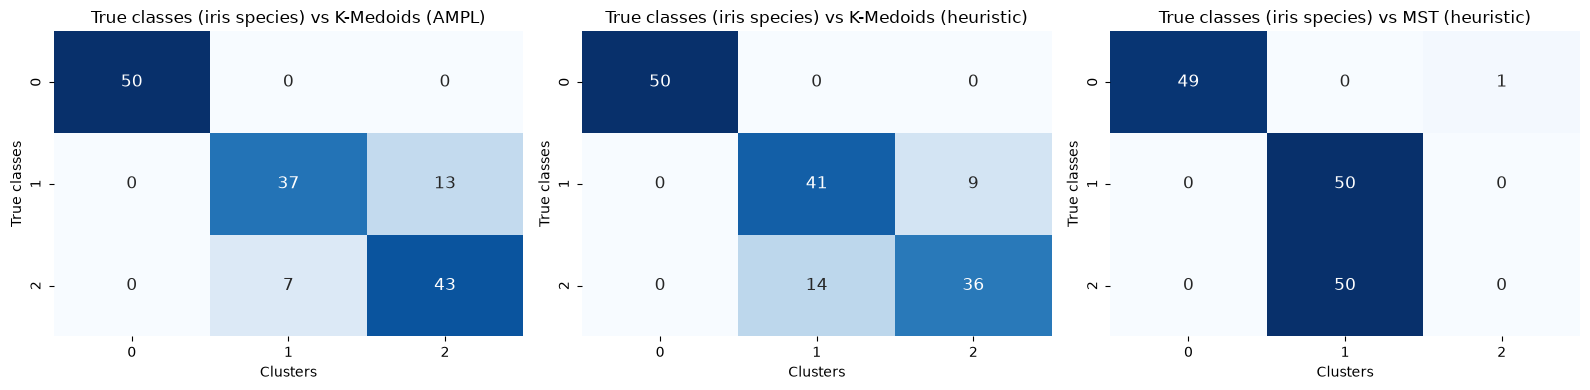

In [40]:
# Re-aligning clusters to compare in the confusion matrix
def align_cluster_labels(y_true, y_pred):
  cm = confusion_matrix(y_true, y_pred)
  row_ind, col_ind = linear_sum_assignment(-cm)
  mapping = {col: row for row, col in zip(row_ind, col_ind)}
  return np.array([mapping.get(label, label) for label in y_pred])


# Display
fig, axes = plt.subplots(1, len(methods), figsize=(16, 4))

for ax, (name, labels) in zip(axes, methods.items()):
  # Re-aligning
  labels_aligned = align_cluster_labels(y, labels)
  cm = confusion_matrix(y, labels_aligned)

  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      cbar=False,
      ax=ax,
      annot_kws={"size": 12},
  )
  ax.set_title(f"True classes (iris species) vs {name}")
  ax.set_xlabel("Clusters")
  ax.set_ylabel("True classes")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [41]:
D = euclidean_distances(X, X)

# Computing the objective function:
def medoid_objective(D, labels):
    """Somme des distances de chaque point au médoïde de son cluster.
    Le médoïde d'un cluster est le membre qui minimise la somme des
    distances aux autres membres. Renvoie (objectif, indices 0-based)."""
    labels = np.asarray(labels)
    total, medoids = 0.0, []
    for c in np.unique(labels):
        members = np.where(labels == c)[0]
        sub = D[np.ix_(members, members)]
        medoid = members[sub.sum(axis=0).argmin()]
        medoids.append(medoid)
        total += D[members, medoid].sum()
    return total, medoids

# Results:
rows = []
for name, labels in methods.items():
    obj, med = medoid_objective(D, labels)
    rows.append({
        "Method": name,
        "Objective": round(obj, 4),
        "Medoids (1-based)": sorted(int(i) + 1 for i in med),
        "ARI vs species": round(adjusted_rand_score(y, labels), 3),
        "ARI vs AMPL": round(adjusted_rand_score(ampl_labels, labels), 3),
    })

results = pd.DataFrame(rows)
print(results.to_string(index=False))

print("Identical PAM inertia :", np.isclose(medoid_objective(D, labels_heur_kmed)[0],
                                              kmedoids.inertia_))

               Method  Objective Medoids (1-based)  ARI vs species  ARI vs AMPL
     K-Medoids (AMPL)   130.2968      [8, 95, 148]           0.676        1.000
K-Medoids (heuristic)   131.3558      [8, 56, 113]           0.642        0.802
      MST (heuristic)   158.9241      [8, 42, 127]           0.558        0.564
Identical PAM inertia : True


## Comparison of the solution time for the heuristics

In [42]:
num_iterations = 20

print(
    f"Benchmark on {num_iterations} iterations"
)

# K-medoids (heuristic)
kmed_times = []
for i in range(num_iterations):
  start = time.perf_counter()
  kmed = KMedoids(n_clusters=3, random_state=42).fit(X)
  labels_heur_kmed = kmed.labels_
  end = time.perf_counter()
  kmed_times.append(end - start)


# MST (heuristic with scipy)
mst_times = []
for _ in range(num_iterations):
  start = time.perf_counter()
  dist_matrix = squareform(pdist(X))
  mst_matrix = minimum_spanning_tree(dist_matrix)
  mst_coo = mst_matrix.tocoo()
  edges = sorted(
      zip(mst_coo.row, mst_coo.col, mst_coo.data),
      key=lambda x: x[2],
      reverse=True,
  )
  edges_to_keep = edges[3 - 1 :]  # k-1 edges to cut with k=3
  row = [e[0] for e in edges_to_keep] + [e[1] for e in edges_to_keep]
  col = [e[1] for e in edges_to_keep] + [e[0] for e in edges_to_keep]
  data = [e[2] for e in edges_to_keep] + [e[2] for e in edges_to_keep]
  pruned_mst = sp.coo_matrix((data, (row, col)), shape=dist_matrix.shape).tocsr()
  _, labels_heur_mst = connected_components(
      pruned_mst, directed=False, return_labels=True
  )
  end = time.perf_counter()
  mst_times.append(end - start)
from sklearn.cluster import AgglomerativeClustering

# MST (heuristic with sklearn)
agg_mst_times = []
for _ in range(num_iterations):
  start = time.perf_counter()
  agg = AgglomerativeClustering(n_clusters=3, linkage="single")
  labels_agg = agg.fit_predict(X)
  end = time.perf_counter()
  agg_mst_times.append(end - start)

# Results
results = {
    "Method": [
        "K-Medoids (heuristic)",
        "MST (heuristic with scipy)",
        "MST (heuristic with sklearn)",
    ],
    "Average time (s)": [
        np.mean(kmed_times),
        np.mean(mst_times),
        np.mean(agg_mst_times),
    ],
    "Standard error (s)": [
        np.std(kmed_times),
        np.std(mst_times),
        np.std(agg_mst_times),
    ],
}

df_bench = pd.DataFrame(results)

print("\n")
print(df_bench.to_string(index=False))
df_bench.to_csv("time_comparison.csv", index=False)


Benchmark on 20 iterations


                      Method  Average time (s)  Standard error (s)
       K-Medoids (heuristic)          0.003236            0.001142
  MST (heuristic with scipy)          0.004354            0.000515
MST (heuristic with sklearn)          0.000908            0.000133
